### Figure 2: beta and beta-binomial distributions

This code plots examples of the beta and beta-binomial distributions.

In [1]:
# Import statements
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import betabinom, beta as beta_dist
from figstyle import PALETTE, LW, FIGW_DOUBLE, panel_label, save

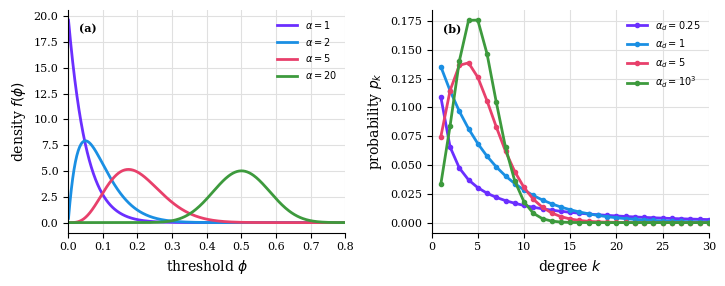

In [ ]:
z = 5.0
fig, axes = plt.subplots(1, 2, figsize=(FIGW_DOUBLE, 2.9))

# Set the range of phi
x = np.linspace(0.001, 0.999, 500) 

# Chosing a few examples with different skews
thr_specs = [
    (1, 20,  r'$\alpha=1$'),
    (2, 20,  r'$\alpha=2$'),
    (5, 20,  r'$\alpha=5$'),
    (20, 20, r'$\alpha=20$'),
]

# Plot beta distribution of thresholds f(phi) vs phi.
for (a, b, lab), col in zip(thr_specs, PALETTE):
    axes[0].plot(x, beta_dist.pdf(x, a, b), color=col, lw=LW, label=lab)

axes[0].set_xlabel('threshold $\\phi$')
axes[0].set_ylabel('density $f(\\phi)$')
axes[0].set_xlim(0, 0.8)
axes[0].legend(frameon=False, loc='upper right', fontsize=7)


# Plot beta-binomial PMFs for <k>=5, starting at k=1.
kk = np.arange(1, 31)

# Choose a few examples with different skews
deg_specs = [
    (0.25, 5,      r'$\alpha_d=0.25$'),
    (1.0,  20,     r'$\alpha_d=1$'),
    (5.0,  95,     r'$\alpha_d=5$'),
    (1000, 100000, r'$\alpha_d=10^3$'),
]

# Plot beta-binomial distributions of degrees p_k vs k.
for (ad, bd, lab), col in zip(deg_specs, PALETTE):
    md = ad/(ad + bd)
    n = int(z/md) # n is (an integer) z/md. 
    axes[1].plot(kk, betabinom.pmf(kk, n, ad, bd), 'o-',
                 color=col, lw=LW, ms=3, label=lab)
    
axes[1].set_xlabel('degree $k$')
axes[1].set_ylabel('probability $p_k$')
axes[1].set_xlim(0, 30)
axes[1].legend(frameon=False, loc='upper right', fontsize=7)

panel_label(axes[0], 'a')
panel_label(axes[1], 'b')
fig.tight_layout()
save(fig, "figure2")
plt.show()

Below, we run some numerical checks.

In [32]:
# We check that the BB PMFs sum to 1, that they have the same <k>, and their variances decrease correctly.
var = []
for ad, bd, _ in deg_specs:
    print(f'For alpha_d={ad:g}:')
    n = max(int(round(z * (ad + bd) / ad)), 2)
    kfull = np.arange(n + 1)
    pk = betabinom.pmf(kfull, n, ad, bd)
    assert abs(pk.sum() - 1) < 1e-9
    print(f"The sum on k of p_k is: {pk.sum():.8g}.")
    mu = (kfull * pk).sum()
    assert abs(mu - z) < 1e-6, f"BB z {mu} != labeled {z}"
    print(f"For a target z of {z:.8g}, we have a true z of {mu:.8g}.")
    var.append(((kfull - mu) ** 2 * pk).sum())
    print(f'The variance is {var[-1]:0.3g}\n.')
assert var[0] > var[1] > var[2] > var[3], "skew progression broken"
print('The variances decrease as alpha_d increases, indicating that the distribution becomes more peaked.')


For alpha_d=0.25:
The sum on k of p_k is: 1.
For a target z of 5, we have a true z of 5.
The variance is 84
.
For alpha_d=1:
The sum on k of p_k is: 1.
For a target z of 5, we have a true z of 5.
The variance is 27.3
.
For alpha_d=5:
The sum on k of p_k is: 1.
For a target z of 5, we have a true z of 5.
The variance is 9.41
.
For alpha_d=1000:
The sum on k of p_k is: 1.
For a target z of 5, we have a true z of 5.
The variance is 4.98
.
The variances decrease as alpha_d increases, indicating that the distribution becomes more peaked.
